<a href="https://colab.research.google.com/github/evelynchopi-ux/NEW-FINAL-REPORT-26-10-26/blob/main/NEW_FINAL_REPORT_26_10_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PPE detection with YOLOv8
Zip of images + LabelMe JSONs → YOLO dataset → train → test → save

In [ ]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os, json, glob, random, shutil, zipfile
from collections import Counter
from PIL import Image

# ---- CONFIG (edit these) ----
CLASSES  = ['boots', 'gloves', 'goggles', 'helmets', 'lab_coats', 'masks', 'vests', 'work_suits']
ZIP_PATH = "/content/drive/MyDrive/PPE.zip"        # <- path to your zip
LABELS_DIR = "/content/drive/MyDrive/dataset"      # <- where the LabelMe JSONs live (searched recursively)
RAW_DIR  = "/content/PPE_raw"                      # unzipped here
OUT_DIR  = "/content/dataset"                      # YOLO dataset built here
RUNS_DIR = "/content/drive/MyDrive/PROGRESS/runs"  # training output (kept on Drive)
VAL_FRAC = 0.2
SEED     = 42

for d in (RAW_DIR, OUT_DIR):
    shutil.rmtree(d, ignore_errors=True)
with zipfile.ZipFile(ZIP_PATH) as z:
    z.extractall(RAW_DIR)
print("Unzipped to", RAW_DIR)

Unzipped to /content/PPE_raw


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ---- Pair every image (from the zip) with its JSON (from LABELS_DIR) by base name ----
IMG_EXT = ('.jpg', '.jpeg', '.png')
imgs, jsons = {}, {}

def scan(folder, want_imgs, want_jsons):
    for root, dirs, files in os.walk(folder):
        dirs[:] = [d for d in dirs if d != "__MACOSX"]
        for f in sorted(files):
            if f.startswith("._"):
                continue
            stem, ext = os.path.splitext(f)
            if want_imgs and ext.lower() in IMG_EXT:
                imgs.setdefault(stem.lower(), os.path.join(root, f))     # first copy wins (dedupes)
            elif want_jsons and ext.lower() == ".json":
                if stem.lower().endswith(IMG_EXT):                       # handles "name.jpg.json"
                    stem = os.path.splitext(stem)[0]
                jsons.setdefault(stem.lower(), os.path.join(root, f))

scan(RAW_DIR, want_imgs=True, want_jsons=True)       # images (and any JSONs) inside the zip
scan(LABELS_DIR, want_imgs=False, want_jsons=True)   # JSONs on Drive

pairs = [(imgs[k], jsons[k]) for k in sorted(imgs) if k in jsons]
print(f"Images: {len(imgs)} | JSONs: {len(jsons)} | Matched pairs: {len(pairs)}")
print(f"Images without JSON: {len(set(imgs) - set(jsons))} | JSONs without image: {len(set(jsons) - set(imgs))}")
if not pairs:
    print("Example image names:", list(imgs)[:3])
    print("Example JSON names: ", list(jsons)[:3])
    raise SystemExit("No matches - check LABELS_DIR and that image/JSON base names agree.")

random.seed(SEED)
random.shuffle(pairs)
split = int(len(pairs) * (1 - VAL_FRAC))
splits = {"train": pairs[:split], "val": pairs[split:]}
print({k: len(v) for k, v in splits.items()})

Images: 1409 | JSONs: 1401 | Matched pairs: 1401
Images without JSON: 8 | JSONs without image: 0
{'train': 1120, 'val': 281}


In [ ]:
# ---- Convert LabelMe polygons/rectangles -> YOLO boxes, write into YOLO folder layout ----
def norm(s):  # case / underscore / plural tolerant label matching
    return s.strip().lower().replace('_', '').replace(' ', '').rstrip('s')

class_lookup = {norm(c): i for i, c in enumerate(CLASSES)}
stats, unknown = Counter(), Counter()
box_counts = {"train": Counter(), "val": Counter()}

for split_name, items in splits.items():
    img_dir = os.path.join(OUT_DIR, "images", split_name)
    lbl_dir = os.path.join(OUT_DIR, "labels", split_name)
    os.makedirs(img_dir, exist_ok=True)
    os.makedirs(lbl_dir, exist_ok=True)

    for img_path, json_path in items:
        base, ext = os.path.splitext(os.path.basename(img_path))
        dst = os.path.join(img_dir, base + ext.lower())
        shutil.copy2(img_path, dst)
        with Image.open(dst) as im:
            W, H = im.size

        with open(json_path) as f:
            data = json.load(f)

        lines = []
        for s in data.get("shapes", []):
            label = s.get("label") or ""
            cid = class_lookup.get(norm(label))
            if cid is None:
                unknown[label] += 1
                continue
            pts = s.get("points", [])
            if len(pts) < 2:
                stats["bad_shape"] += 1
                continue
            xs, ys = [p[0] for p in pts], [p[1] for p in pts]
            x1, x2 = max(0, min(xs)), min(W, max(xs))
            y1, y2 = max(0, min(ys)), min(H, max(ys))
            if x2 - x1 < 2 or y2 - y1 < 2:
                stats["degenerate_box"] += 1
                continue
            lines.append(f"{cid} {(x1+x2)/2/W:.6f} {(y1+y2)/2/H:.6f} {(x2-x1)/W:.6f} {(y2-y1)/H:.6f}")
            box_counts[split_name][CLASSES[cid]] += 1

        if not lines:
            stats["images_with_no_boxes"] += 1
        with open(os.path.join(lbl_dir, base + ".txt"), "w") as f:
            f.write("\n".join(lines))

yaml_path = os.path.join(OUT_DIR, "data.yaml")
with open(yaml_path, "w") as f:
    f.write(f"path: {OUT_DIR}\ntrain: images/train\nval: images/val\n")
    f.write(f"nc: {len(CLASSES)}\nnames: {CLASSES}\n")

print("Issues:", dict(stats) or "none")
print("Unknown labels (skipped):", dict(unknown) or "none")
print("Train boxes:", dict(box_counts["train"]))
print("Val boxes:  ", dict(box_counts["val"]))

Issues: {'degenerate_box': 24}
Unknown labels (skipped): none
Train boxes: {'lab_coats': 381, 'work_suits': 327, 'vests': 393, 'masks': 373, 'helmets': 232, 'boots': 130, 'gloves': 217, 'goggles': 74}
Val boxes:   {'vests': 110, 'helmets': 77, 'lab_coats': 84, 'masks': 100, 'goggles': 20, 'gloves': 46, 'work_suits': 66, 'boots': 24}


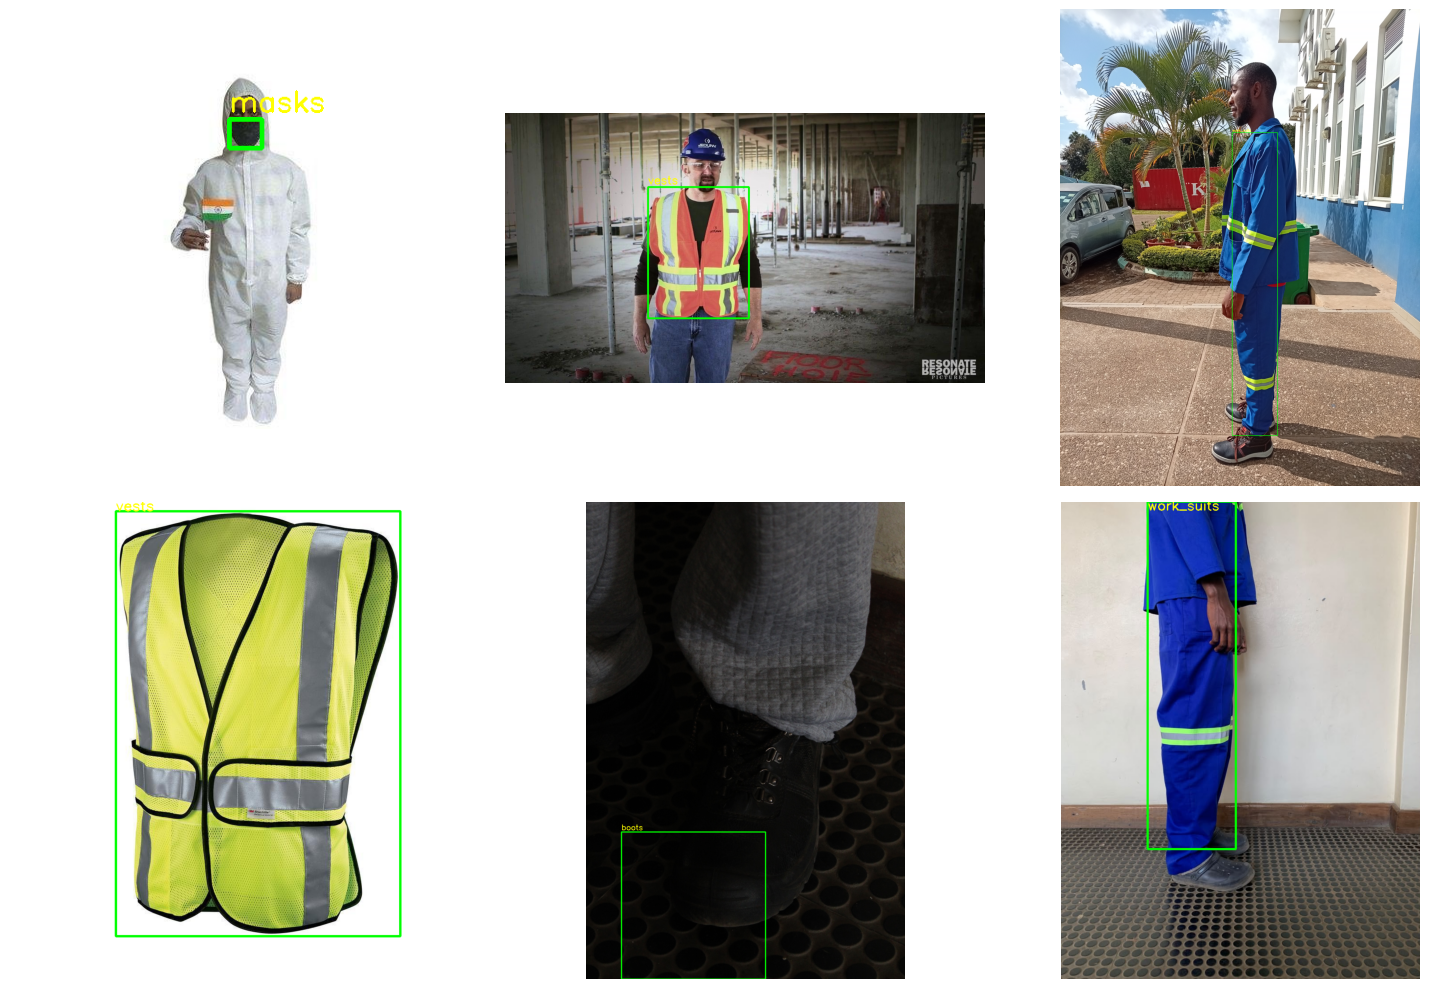

In [ ]:
# ---- Sanity check: draw labels on a few training images ----
import cv2, matplotlib.pyplot as plt

img_dir, lbl_dir = f"{OUT_DIR}/images/train", f"{OUT_DIR}/labels/train"
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
for ax, p in zip(axes.flat, random.sample(glob.glob(f"{img_dir}/*"), 6)):
    img = cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)
    H, W = img.shape[:2]
    lbl = os.path.join(lbl_dir, os.path.splitext(os.path.basename(p))[0] + ".txt")
    for line in open(lbl).read().split("\n"):
        if not line.strip(): continue
        c, xc, yc, w, h = line.split()
        xc, yc, w, h = float(xc)*W, float(yc)*H, float(w)*W, float(h)*H
        x1, y1, x2, y2 = int(xc-w/2), int(yc-h/2), int(xc+w/2), int(yc+h/2)
        cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 3)
        cv2.putText(img, CLASSES[int(c)], (x1, max(y1-8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 0), 2)
    ax.imshow(img); ax.axis("off")
plt.tight_layout(); plt.show()

In [ ]:
# ---- Train ----
from ultralytics import YOLO

# Option A (fast baseline): yolov8s @ 640   | Option B (more accurate): yolov8m @ 960, batch 8
MODEL, EPOCHS, IMGSZ, BATCH = "yolov8s.pt", 100, 640, 16
# MODEL, EPOCHS, IMGSZ, BATCH = "yolov8m.pt", 150, 960, 8

model = YOLO(MODEL)
model.train(
    data=yaml_path,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    patience=20,                 # early stop if val stops improving
    device=0,
    project=RUNS_DIR,            # on Drive, so a disconnect doesn't lose progress
    name="ppe",
    exist_ok=False,
)
best_weights = str(model.trainer.best)
print("Best weights:", best_weights)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, f

In [ ]:
# ---- Test on an image ----
import cv2
from google.colab.patches import cv2_imshow

model = YOLO(best_weights)
results = model.predict(source="/content/drive/MyDrive/TEST_IMAGE_6.jpg", conf=0.35)
cv2_imshow(results[0].plot())

In [ ]:
# ---- Save weights to Drive + download ----
from google.colab import files

backup = "/content/drive/MyDrive/PROGRESS/ppe_best.pt"
os.makedirs(os.path.dirname(backup), exist_ok=True)
shutil.copy2(best_weights, backup)
print("Saved to", backup)
files.download(best_weights)

Saved to /content/drive/MyDrive/PROGRESS/ppe_best.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
!pip install -q ultralytics
from ultralytics import YOLO
from google.colab import files
import cv2

uploaded = files.upload()              # pick your best.pt
best_weights = next(iter(uploaded))    # e.g. "best.pt"

Saving best.pt to best.pt


<IPython.core.display.Javascript object>


image 1/1 /content/capture.jpg: 480x640 1 vests, 21.7ms
Speed: 0.8ms preprocess, 21.7ms inference, 1.3ms postprocess per image at shape (1, 3, 480, 640)


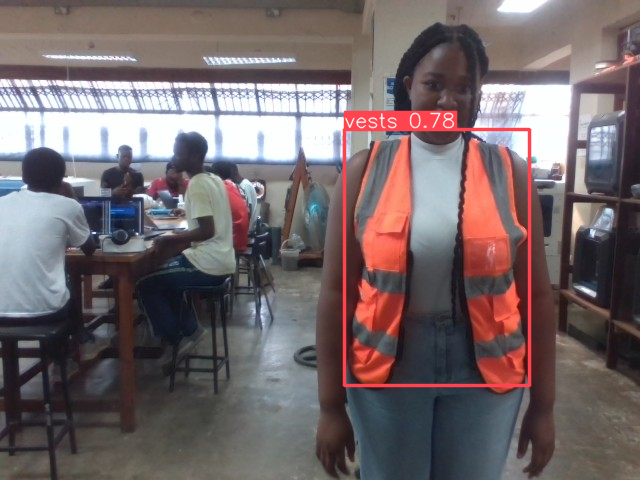

In [11]:
# ---- Test: capture a photo from your webcam, then detect ----
!pip install -q ultralytics
from ultralytics import YOLO
from IPython.display import display, Javascript
from google.colab.output import eval_js
from google.colab.patches import cv2_imshow
from base64 import b64decode
import cv2
import os

def take_photo(filename="capture.jpg", quality=0.9):
    display(Javascript("""
    async function takePhoto(quality) {
      const div = document.createElement('div');
      const btn = document.createElement('button');
      btn.textContent = 'Capture';
      div.appendChild(btn);
      const video = document.createElement('video');
      video.style.display = 'block';
      const stream = await navigator.mediaDevices.getUserMedia({video: true});
      document.body.appendChild(div);
      div.appendChild(video);
      video.srcObject = stream;
      await video.play();
      google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
      await new Promise((resolve) => btn.onclick = resolve);
      const canvas = document.createElement('canvas');
      canvas.width = video.videoWidth;
      canvas.height = video.videoHeight;
      canvas.getContext('2d').drawImage(video, 0, 0);
      stream.getVideoTracks()[0].stop();
      div.remove();
      return canvas.toDataURL('image/jpeg', quality);
    }
    """))
    data = eval_js(f"takePhoto({quality})")
    with open(filename, "wb") as f:
        f.write(b64decode(data.split(",")[1]))
    return filename

# Fallback to the saved best weights path on Drive if the variable is not in memory
if 'best_weights' not in globals():
    best_weights = "/content/drive/MyDrive/PROGRESS/ppe_best.pt"
    print(f"'best_weights' variable not found in memory. Using backup path: {best_weights}")

model = YOLO(best_weights)
photo = take_photo()
results = model.predict(source=photo, conf=0.60)
cv2_imshow(results[0].plot())